# Exercise 7 — Text Clustering
- **K-Means**
- **Hierarchical Clustering:** Single, Complete, Average, dan Ward
- Evaluasi menggunakan **Silhouette Score**
- Visualisasi **Elbow Method**, dendrogram, distribusi anggota cluster, dan WordCloud.

Menggunakan tiga representasi fitur dari Exercise 5: TF-IDF, Word2Vec, dan FastText.


## 1. Instalasi library


In [4]:
!pip -q install gensim wordcloud nltk scikit-learn scipy pandas matplotlib seaborn

## 2. Import library dan konfigurasi

Jumlah cluster dibuat **4** agar perbandingan antar-metode konsisten.

In [5]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from wordcloud import WordCloud

import gensim
from gensim.models import Word2Vec, FastText

warnings.filterwarnings('ignore')

RANDOM_STATE = 10
N_CLUSTERS = 4

MAX_HIERARCHICAL_SAMPLES = None

print('Library berhasil diimpor.')

Library berhasil diimpor.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 3. Upload dataset



In [6]:
CSV_PATH = '/content/hasil_preprocessing_youtube.csv'

df = pd.read_csv(CSV_PATH)

if 'comment' not in df.columns:
    raise ValueError(
        f"Kolom 'comment' tidak ditemukan. Kolom tersedia: {list(df.columns)}"
    )

df = df.dropna(subset=['comment']).copy()
df['comment'] = df['comment'].astype(str).str.strip()
df = df[df['comment'] != ''].reset_index(drop=True)

df_pre = df['comment']

print('Dataset:', CSV_PATH)
print('Jumlah komentar:', len(df))

display(df.head())

Dataset: /content/hasil_preprocessing_youtube.csv
Jumlah komentar: 3334


,author,comment,likes,published_at,reply_count,is_reply,text,rm_html,rm_mention,rm_hashtag,lower_case,rm_url,rm_emoji,rm_punc,rm_repeat,norm,tokens,tokens_no_stopword,stemming,text_final
0,@nasiangkasa,Dalam Video ini mungkin kalian menyadari bahwa...,1435,2025-07-15T02:30:26Z,255,False,Dalam Video ini mungkin kalian menyadari bahwa...,Dalam Video ini mungkin kalian menyadari bahwa...,Dalam Video ini mungkin kalian menyadari bahwa...,Dalam Video ini mungkin kalian menyadari bahwa...,dalam video ini mungkin kalian menyadari bahwa...,dalam video ini mungkin kalian menyadari bahwa...,dalam video ini mungkin kalian menyadari bahwa...,dalam video ini mungkin kalian menyadari bahwa...,dalam video ini mungkin kalian menyadari bahwa...,dalam video ini mungkin kalian menyadari bahwa...,"['dalam', 'video', 'ini', 'mungkin', 'kalian',...","['video', 'menyadari', 'evolusi', 'manusia', '...","['video', 'sadar', 'evolusi', 'manusia', 'baha...",video sadar evolusi manusia bahas dalam topik ...
1,@andryantz_story,Kocak....cerita seblm tidur....\nCeritain kisa...,13,2025-07-15T11:36:28Z,0,True,Kocak....cerita seblm tidur....\nCeritain kisa...,Kocak....cerita seblm tidur....\nCeritain kisa...,Kocak....cerita seblm tidur....\nCeritain kisa...,Kocak....cerita seblm tidur....\nCeritain kisa...,kocak....cerita seblm tidur....\nceritain kisa...,kocak....cerita seblm tidur....\nceritain kisa...,kocak....cerita seblm tidur....\nceritain kisa...,kocak cerita seblm tidur ceritain kisah nabi a...,kocak cerita seblm tidur ceritain kisah nabi a...,kocak cerita seblm tidur ceritain kisah nabi a...,"['kocak', 'cerita', 'seblm', 'tidur', 'ceritai...","['kocak', 'cerita', 'seblm', 'tidur', 'ceritai...","['kocak', 'cerita', 'seblm', 'tidur', 'cerita'...",kocak cerita seblm tidur cerita kisah nabi ada...
2,@MisterDChannel-q8f,​@andryantz_story Bagus untuk dipelajari tp ja...,14,2025-07-15T12:51:33Z,0,True,​@andryantz_story Bagus untuk dipelajari tp ja...,​@andryantz_story Bagus untuk dipelajari tp ja...,​ Bagus untuk dipelajari tp jangan sampai mena...,​ Bagus untuk dipelajari tp jangan sampai mena...,​ bagus untuk dipelajari tp jangan sampai mena...,​ bagus untuk dipelajari tp jangan sampai mena...,​ bagus untuk dipelajari tp jangan sampai mena...,​ bagus untuk dipelajari tp jangan sampai mena...,​ bagus untuk dipelajari tp jangan sampai mena...,​ bagus untuk dipelajari tp jangan sampai mena...,"['\u200b', 'bagus', 'untuk', 'dipelajari', 'tp...","['\u200b', 'bagus', 'dipelajari', 'tp', 'menaf...","['\u200b', 'bagus', 'dipelajari', 'tp', 'nafi'...",​ bagus dipelajari tp nafi ilmu pengetahu
3,@harihelbi,​@andryantz_storyTunjukan dengan ilmu pengetah...,27,2025-07-15T13:22:48Z,0,True,​@andryantz_storyTunjukan dengan ilmu pengetah...,​@andryantz_storyTunjukan dengan ilmu pengetah...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,​ dengan ilmu pengetahuan anda jangan hanya ko...,"['\u200b', 'dengan', 'ilmu', 'pengetahuan', 'a...","['\u200b', 'ilmu', 'pengetahuan', 'komen', 'me...","['\u200b', 'ilmu', 'pengetahu', 'koman', 'sepe...",​ ilmu pengetahu koman sepele karya orang kala...
4,@Komunitas_Atheis_Madura,"18:50 Dia sedang berkaca, mengagumi dirinya se...",7,2025-07-15T13:37:46Z,0,True,"18:50 Dia sedang berkaca, mengagumi dirinya se...","18:50 Dia sedang berkaca, mengagumi dirinya se...","18:50 Dia sedang berkaca, mengagumi dirinya se...","18:50 Dia sedang berkaca, mengagumi dirinya se...","18:50 dia sedang berkaca, mengagumi dirinya se...","18:50 dia sedang berkaca, mengagumi dirinya se...","18:50 dia sedang berkaca, mengagumi dirinya se...",18 50 dia sedang berkaca mengagumi dirinya sen...,18 50 dia sedang berkaca mengagumi dirinya sen...,18 50 dia sedang berkaca m

## 4. Feature Engineering — TF-IDF

Mengikuti pendekatan Exercise 5 dengan `TfidfVectorizer`.

In [7]:
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(df_pre)

print('Ukuran matriks TF-IDF:', X_tfidf.shape)

Ukuran matriks TF-IDF: (3334, 7639)


## 5. Feature Engineering — Word2Vec

Komentar ditokenisasi, kemudian vektor dokumen dihitung dari rata-rata vektor kata yang tersedia pada model Word2Vec, mengikuti fungsi pada Exercise 5.

In [8]:
sentences = [word_tokenize(tweet.lower()) for tweet in df_pre]

model_w2v = Word2Vec(
    sentences=sentences,
    min_count=1,
    vector_size=100,
    window=5,
    sg=0,
    seed=RANDOM_STATE,
    workers=1
)

def get_document_vector(tokens, model):
    valid_vectors = [
        model.wv[word] for word in tokens
        if word in model.wv
    ]
    if not valid_vectors:
        return np.zeros(model.vector_size, dtype=float)
    return np.mean(valid_vectors, axis=0)

X_w2v = np.array([
    get_document_vector(doc, model_w2v)
    for doc in sentences
])

print('Ukuran matriks Word2Vec:', X_w2v.shape)

Ukuran matriks Word2Vec: (3334, 100)


## 6. Feature Engineering — FastText

FastText juga menggunakan rata-rata vektor kata untuk membentuk vektor dokumen, mengikuti alur Exercise 5.

In [9]:
model_fasttext = FastText(
    sentences=sentences,
    min_count=1,
    vector_size=100,
    window=5,
    min_n=3,
    max_n=6,
    sg=1,
    epochs=10,
    seed=RANDOM_STATE,
    workers=1
)

X_fasttext = np.array([
    get_document_vector(doc, model_fasttext)
    for doc in sentences
])

print('Ukuran matriks FastText:', X_fasttext.shape)

Ukuran matriks FastText: (3334, 100)


## 7. Menyiapkan fitur untuk setiap metode

- K-Means menggunakan matriks.
- Hierarchical untuk TF-IDF menggunakan TruncatedSVD 100 dimensi agar representasi sparse TF-IDF dapat diproses dengan linkage berbasis jarak secara lebih praktis.
- Word2Vec dan FastText menggunakan vektor dokumen 100 dimensi.


In [10]:
svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
X_tfidf_hier = svd.fit_transform(X_tfidf)

feature_sets = {
    'TF-IDF': {
        'kmeans': X_tfidf,
        'hierarchical': X_tfidf_hier
    },
    'Word2Vec': {
        'kmeans': X_w2v,
        'hierarchical': X_w2v
    },
    'FastText': {
        'kmeans': X_fasttext,
        'hierarchical': X_fasttext
    }
}

for name, matrices in feature_sets.items():
    print(name, '| K-Means:', matrices['kmeans'].shape,
          '| Hierarchical:', matrices['hierarchical'].shape)

TF-IDF | K-Means: (3334, 7639) | Hierarchical: (3334, 100)
Word2Vec | K-Means: (3334, 100) | Hierarchical: (3334, 100)
FastText | K-Means: (3334, 100) | Hierarchical: (3334, 100)


## 8. K-Means — Elbow Method

`N_CLUSTERS = 4`

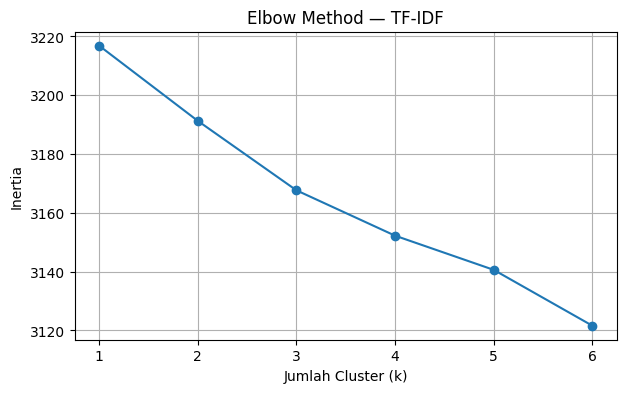

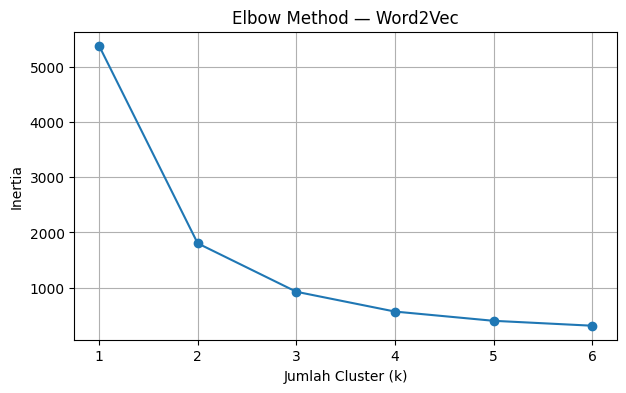

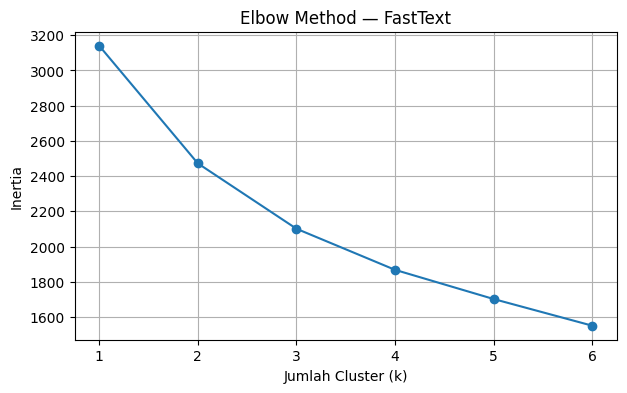

In [11]:
for name, matrices in feature_sets.items():
    X = matrices['kmeans']
    inertias = []

    # Elbow pada TF-IDF sparse maupun embedding.
    for k in range(1, 7):
        km = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )
        km.fit(X)
        inertias.append(km.inertia_)

    plt.figure(figsize=(7, 4))
    plt.plot(range(1, 7), inertias, marker='o')
    plt.title(f'Elbow Method — {name}')
    plt.xlabel('Jumlah Cluster (k)')
    plt.ylabel('Inertia')
    plt.xticks(range(1, 7))
    plt.grid(True)
    plt.show()

## 9. Menjalankan K-Means dan Hierarchical Clustering

Metode Hierarchical yang diuji:
1. Single Linkage
2. Complete Linkage
3. Average Linkage
4. Ward Linkage

Seluruh metode menggunakan jumlah cluster yang sama agar dapat dibandingkan. Silhouette Score dihitung pada ruang fitur yang digunakan untuk clustering.

In [12]:
hierarchical_methods = ['single', 'complete', 'average', 'ward']

results = []
all_labels = {}
data_indices = {}

for feature_name, matrices in feature_sets.items():

    # ---------- K-MEANS ----------
    X_km = matrices['kmeans']

    kmeans = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels_km = kmeans.fit_predict(X_km)

    score_km = silhouette_score(X_km, labels_km)

    key = (feature_name, 'K-Means')
    all_labels[key] = labels_km
    data_indices[key] = np.arange(len(df))

    results.append({
        'Feature Engineering': feature_name,
        'Metode': 'K-Means',
        'Silhouette Score': score_km
    })

    # ---------- HIERARCHICAL ----------
    X_h = matrices['hierarchical']

    # Opsional: batasi jumlah sampel jika RAM Colab tidak cukup.
    if MAX_HIERARCHICAL_SAMPLES is not None and len(df) > MAX_HIERARCHICAL_SAMPLES:
        rng = np.random.default_rng(RANDOM_STATE)
        idx = np.sort(rng.choice(
            len(df), size=MAX_HIERARCHICAL_SAMPLES, replace=False
        ))
        X_run = X_h[idx]
    else:
        idx = np.arange(len(df))
        X_run = X_h

    for method in hierarchical_methods:
        hc = AgglomerativeClustering(
            n_clusters=N_CLUSTERS,
            linkage=method,
            metric='euclidean'
        )
        labels_h = hc.fit_predict(X_run)

        score_h = silhouette_score(X_run, labels_h)

        key = (feature_name, method.title())
        all_labels[key] = labels_h
        data_indices[key] = idx

        results.append({
            'Feature Engineering': feature_name,
            'Metode': method.title(),
            'Silhouette Score': score_h
        })

        print(f'{feature_name} | {method.title()} selesai. '
              f'Silhouette Score = {score_h:.4f}')

results_df = pd.DataFrame(results)
display(
    results_df.sort_values('Silhouette Score', ascending=False)
    .reset_index(drop=True)
)

TF-IDF | Single selesai. Silhouette Score = 0.3128
TF-IDF | Complete selesai. Silhouette Score = 0.2472
TF-IDF | Average selesai. Silhouette Score = 0.3589
TF-IDF | Ward selesai. Silhouette Score = 0.1659
Word2Vec | Single selesai. Silhouette Score = 0.4123
Word2Vec | Complete selesai. Silhouette Score = 0.4498
Word2Vec | Average selesai. Silhouette Score = 0.5080
Word2Vec | Ward selesai. Silhouette Score = 0.5022
FastText | Single selesai. Silhouette Score = 0.3646
FastText | Complete selesai. Silhouette Score = 0.2856
FastText | Average selesai. Silhouette Score = 0.3929
FastText | Ward selesai. Silhouette Score = 0.2712


,Feature Engineering,Metode,Silhouette Score
0,Word2Vec,K-Means,0.517244
1,Word2Vec,Average,0.508049
2,Word2Vec,Ward,0.502242
3,Word2Vec,Complete,0.449840
4,Word2Vec,Single,0.412329
5,FastText,Average,0.392911
6,FastText,Single,0.364599
7,TF-IDF,Average,0.358932
8,TF-IDF,Single,0.312821
9,FastText,Complete,0.285600


## 10. Distribusi anggota cluster


In [13]:
for key, labels in all_labels.items():
    print(f'\\n{key[0]} — {key[1]}')
    counts = pd.Series(labels).value_counts().sort_index()
    display(counts.rename('Jumlah komentar').to_frame())

\nTF-IDF — K-Means


,Jumlah komentar
0,2082
1,1027
2,122
3,103


\nTF-IDF — Single


,Jumlah komentar
0,3327
1,1
2,5
3,1


\nTF-IDF — Complete


,Jumlah komentar
0,3179
1,47
2,98
3,10


... (20 outputs left out)

\nFastText — Average


,Jumlah komentar
0,3268
1,4
2,61
3,1


\nFastText — Ward


,Jumlah komentar
0,2541
1,309
2,118
3,366


## 11. Dendrogram Hierarchical Clustering



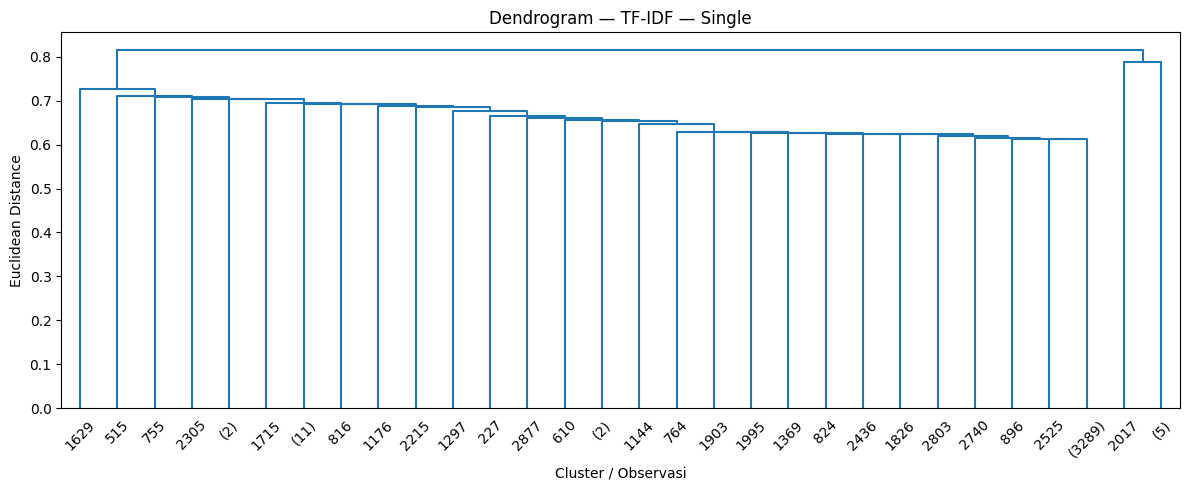

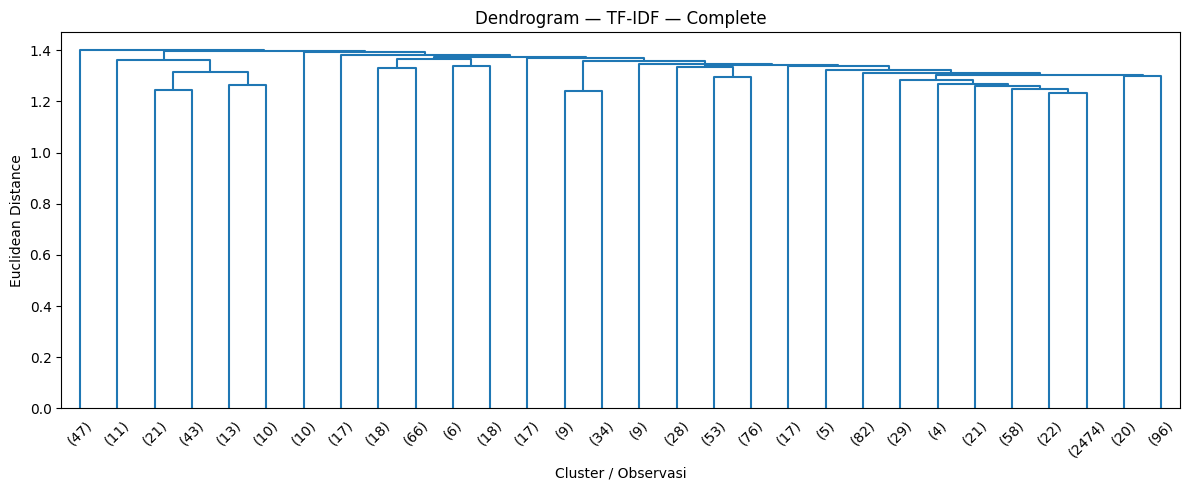

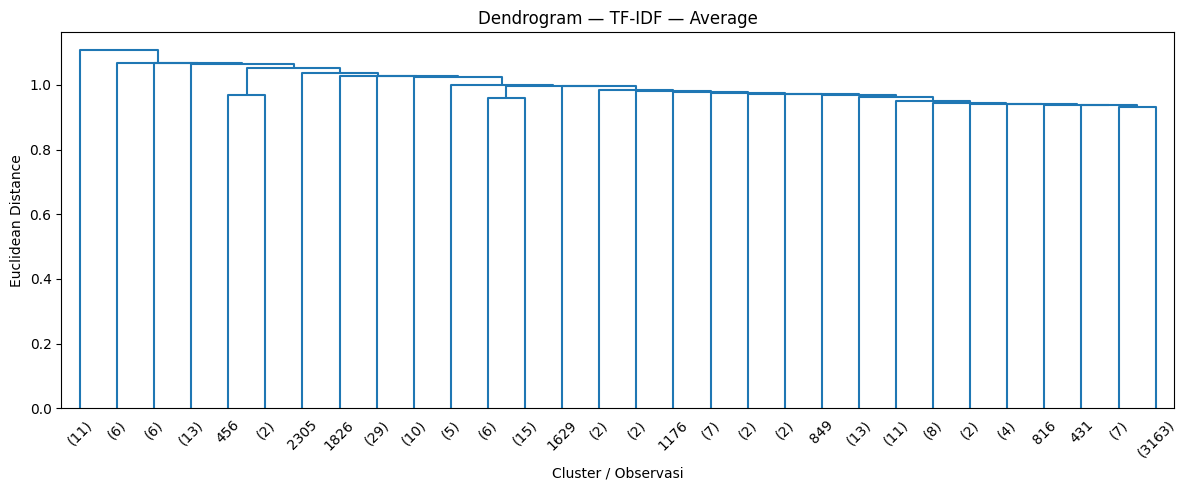

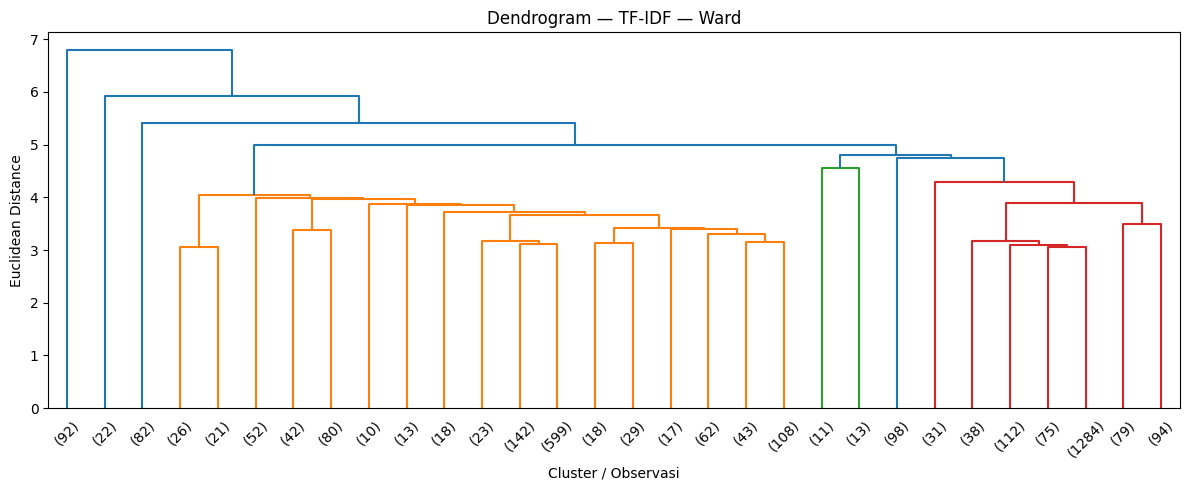

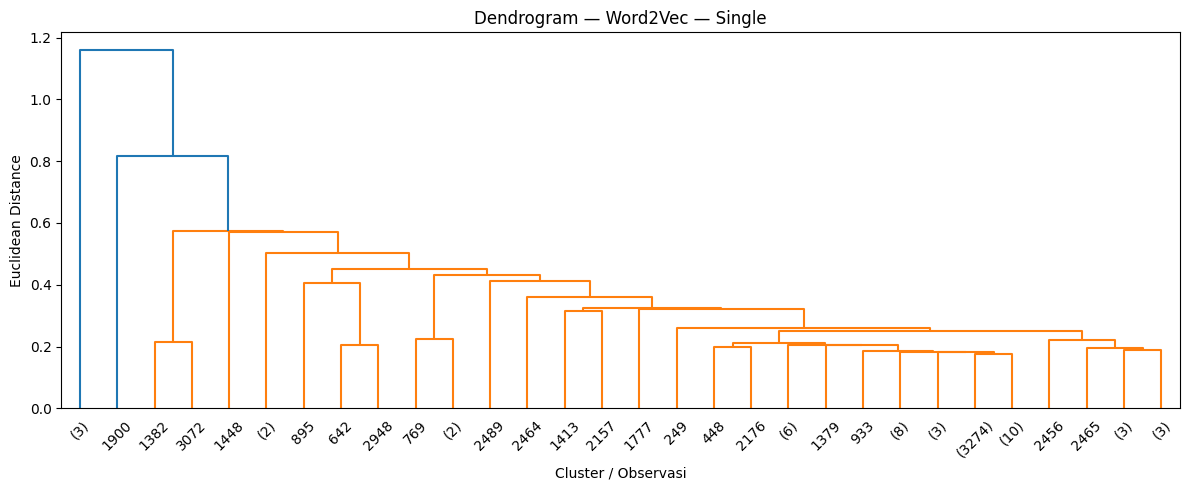

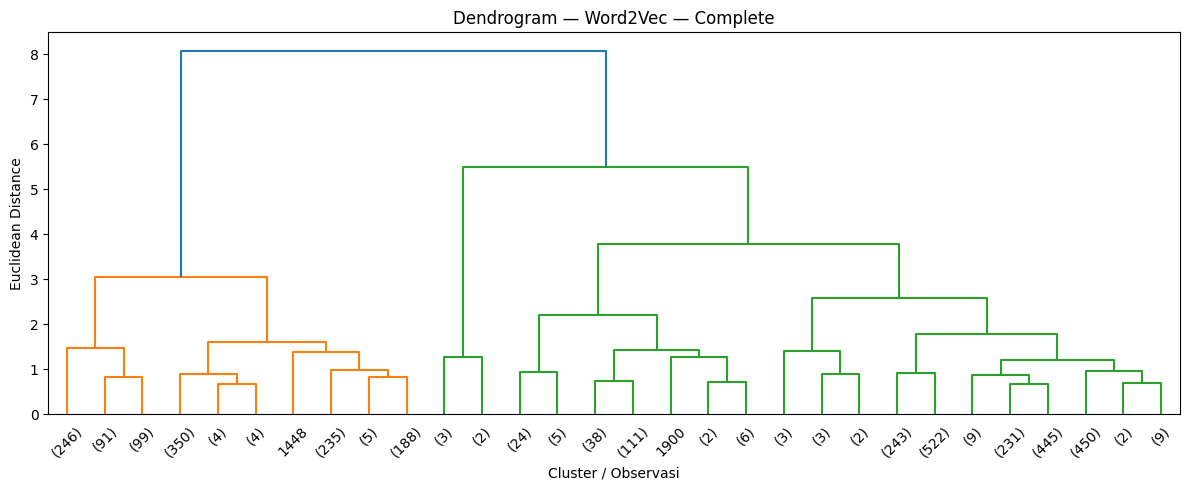

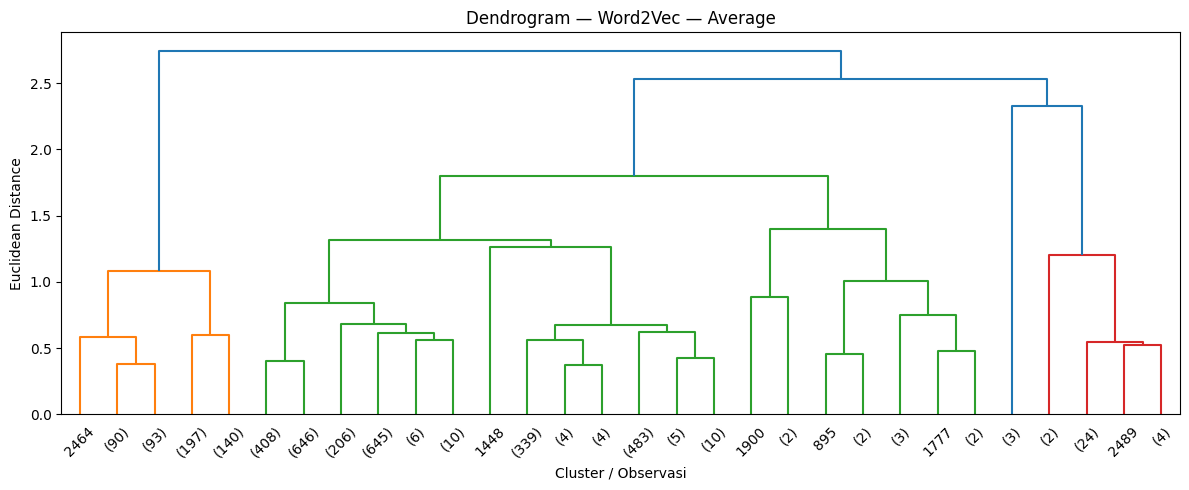

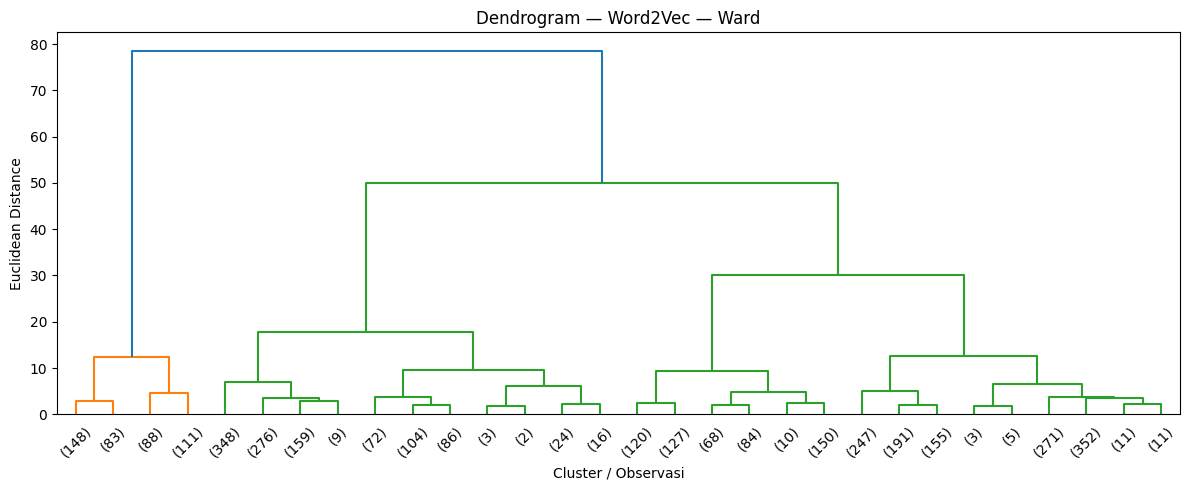

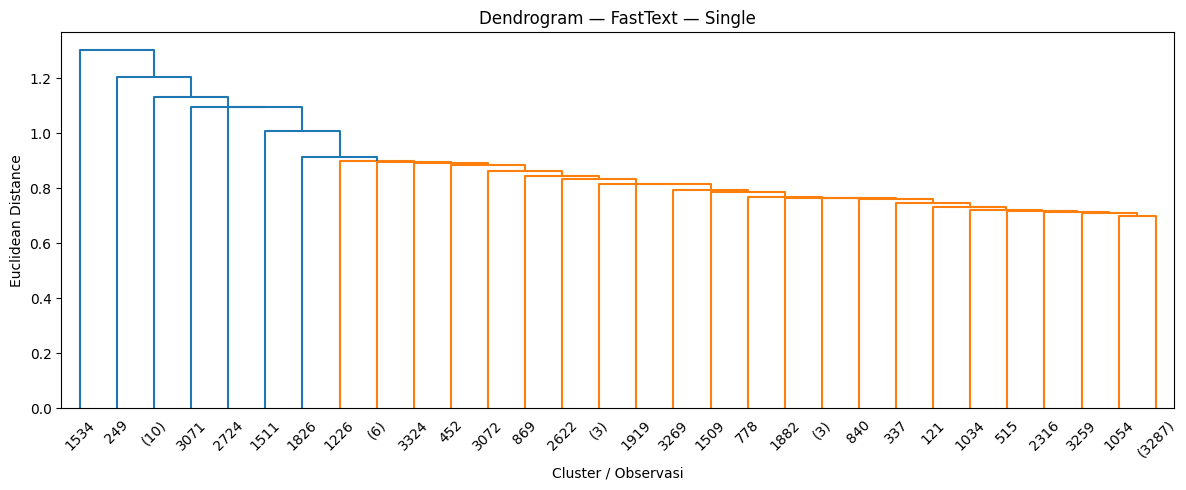

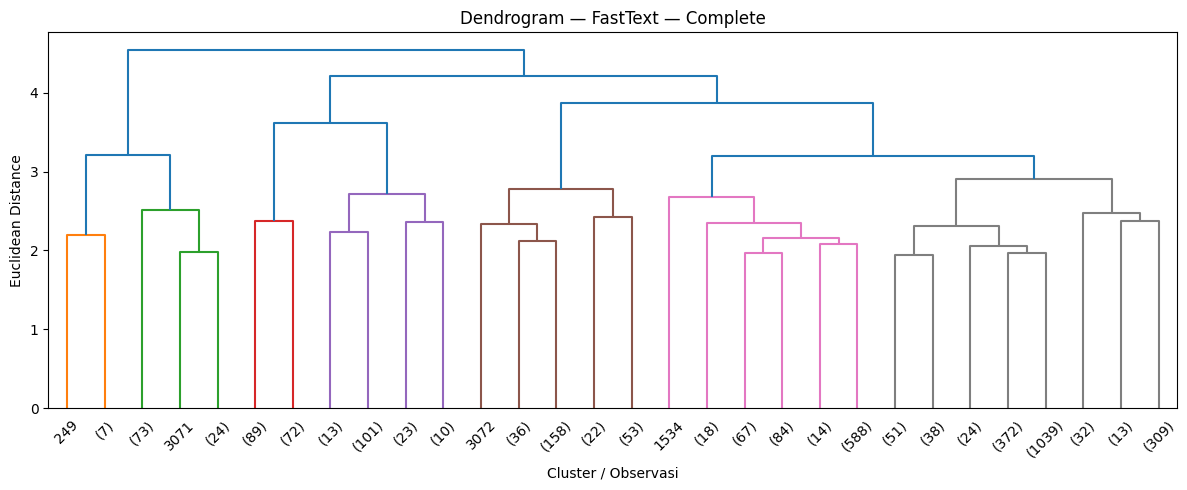

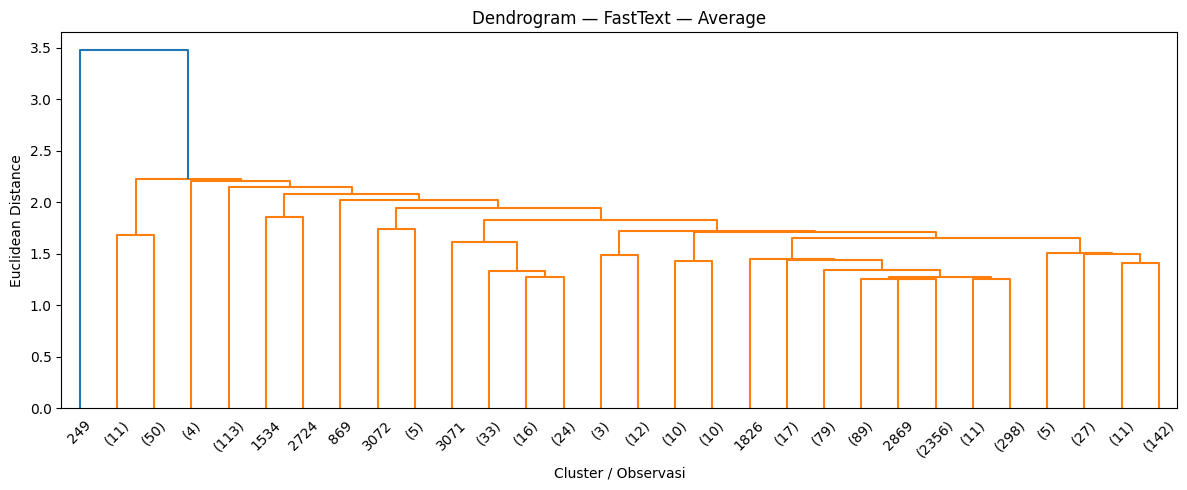

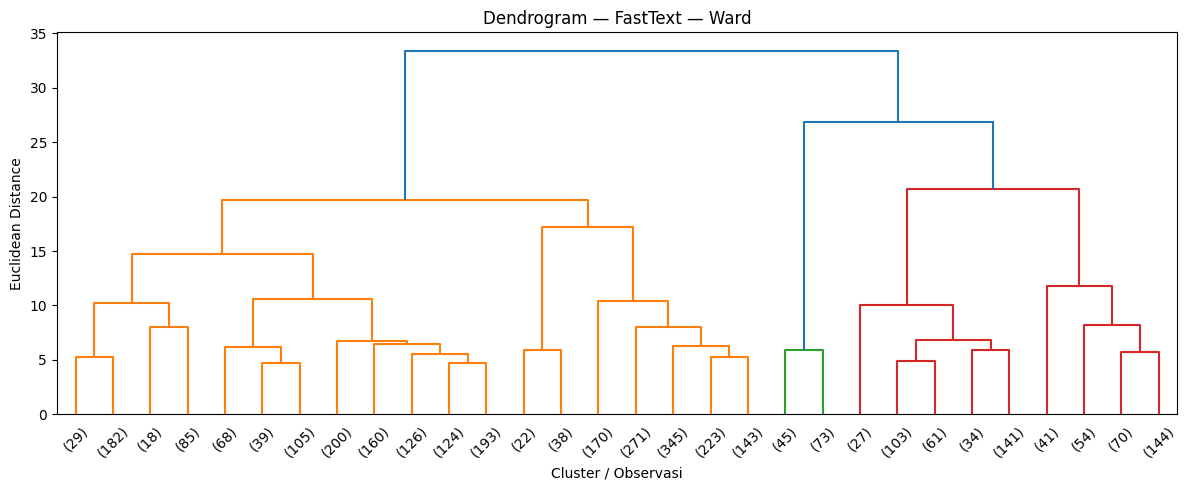

In [14]:
for feature_name, matrices in feature_sets.items():
    X_h = matrices['hierarchical']

    if MAX_HIERARCHICAL_SAMPLES is not None and len(df) > MAX_HIERARCHICAL_SAMPLES:
        rng = np.random.default_rng(RANDOM_STATE)
        idx = np.sort(rng.choice(
            len(df), size=MAX_HIERARCHICAL_SAMPLES, replace=False
        ))
        X_run = X_h[idx]
    else:
        X_run = X_h

    for method in hierarchical_methods:
        Z = linkage(X_run, method=method, metric='euclidean')

        plt.figure(figsize=(12, 5))
        dendrogram(Z, truncate_mode='lastp', p=30)
        plt.title(f'Dendrogram — {feature_name} — {method.title()}')
        plt.xlabel('Cluster / Observasi')
        plt.ylabel('Euclidean Distance')
        plt.tight_layout()
        plt.show()

## 12. WordCloud setiap cluster



WordCloud: TF-IDF - K-Means


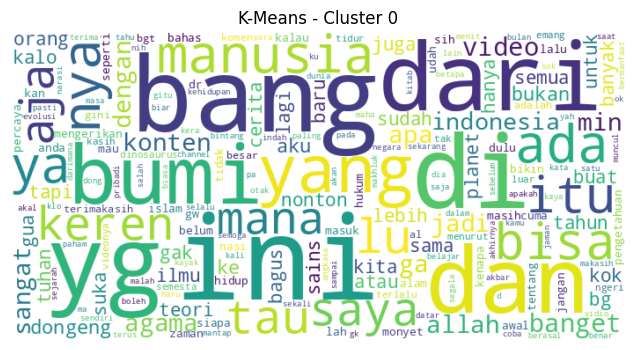

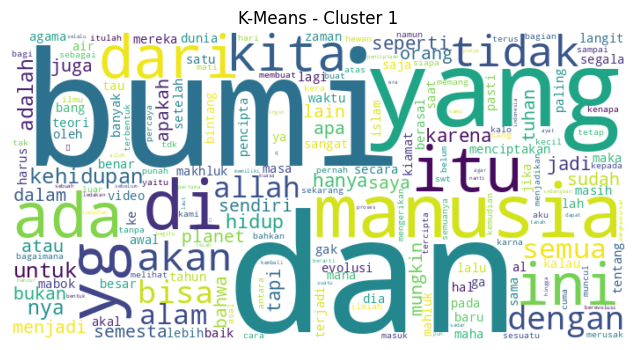

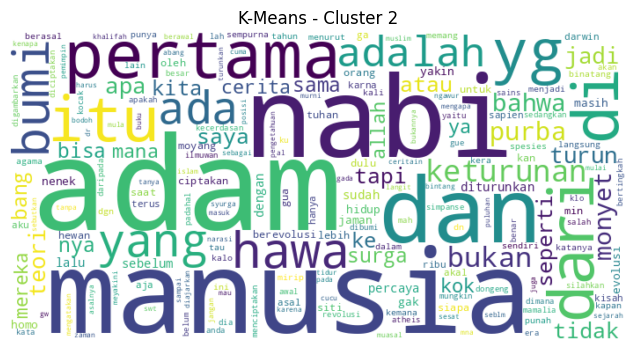

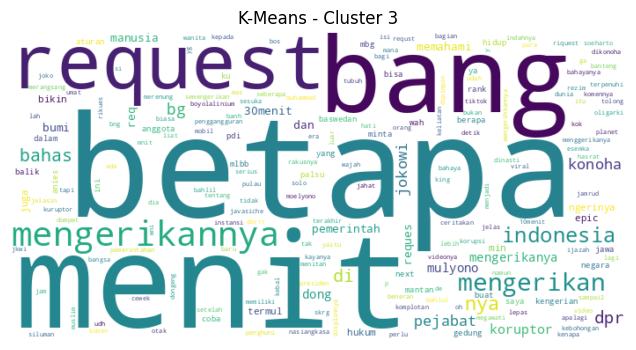

WordCloud: TF-IDF - Single


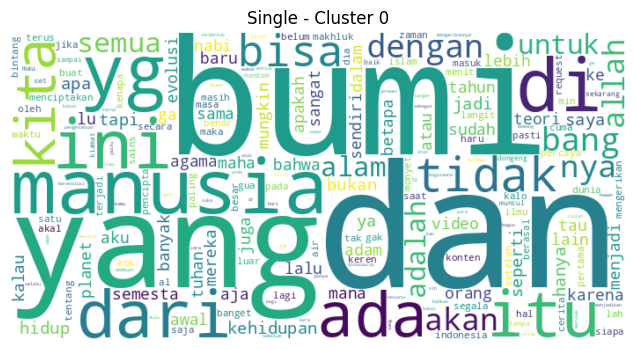

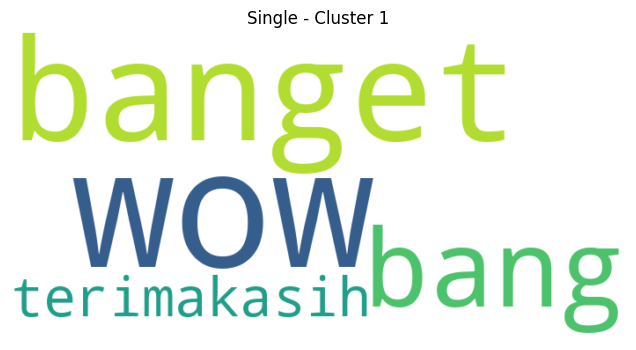

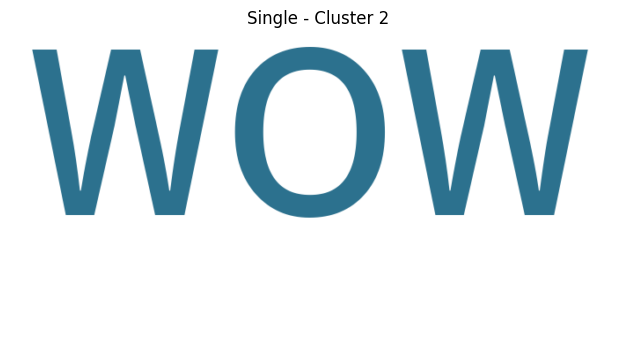

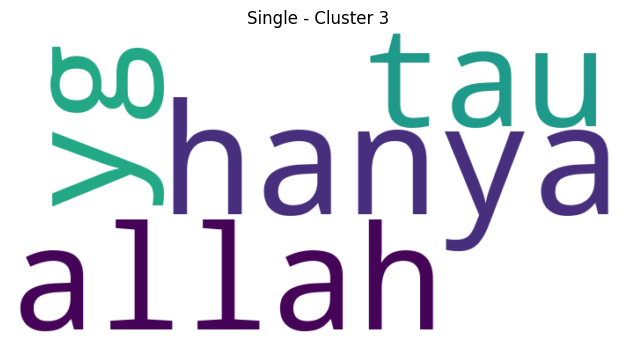

WordCloud: TF-IDF - Complete


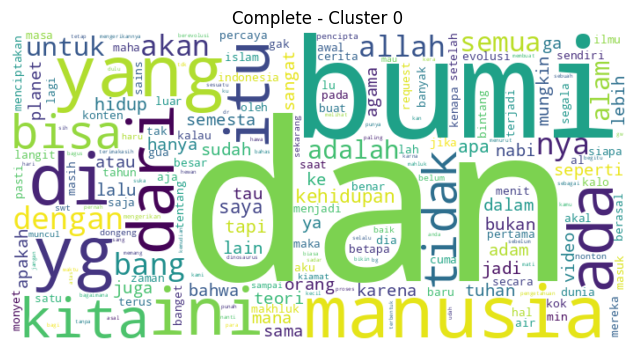

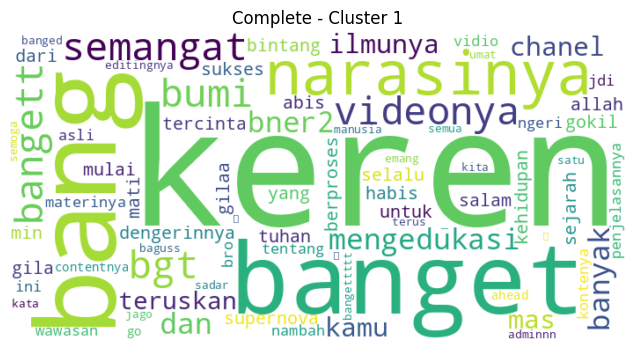

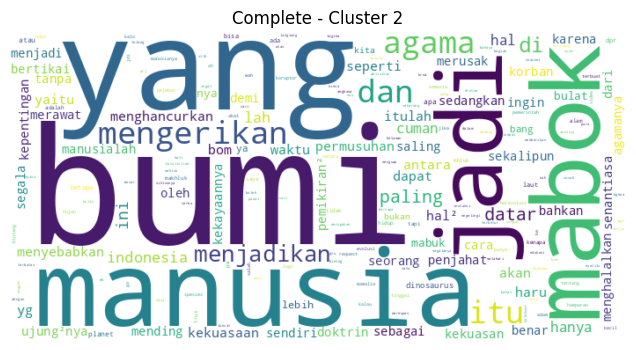

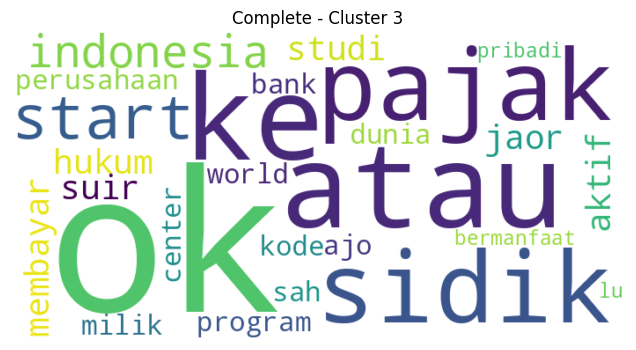

WordCloud: TF-IDF - Average


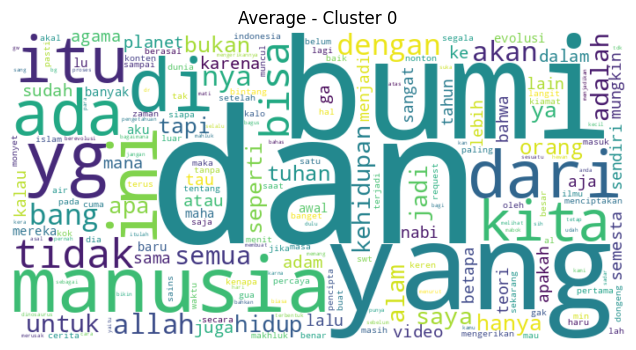

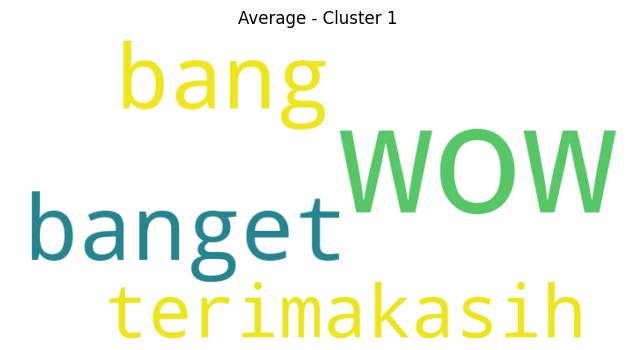

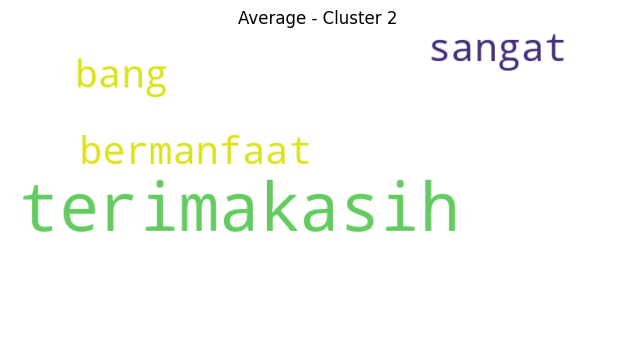

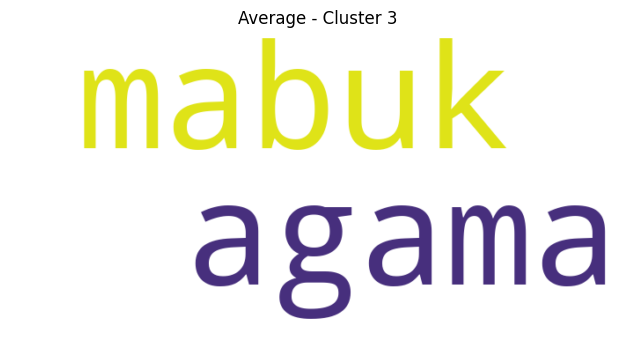

WordCloud: TF-IDF - Ward


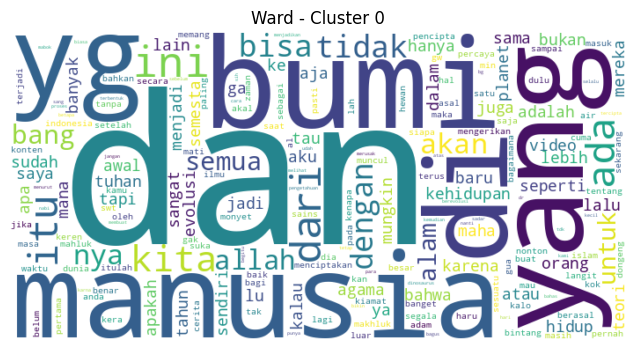

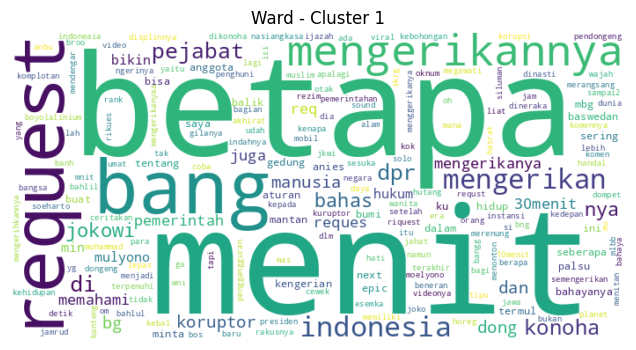

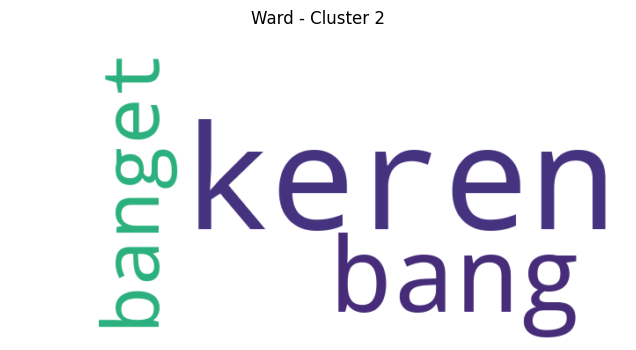

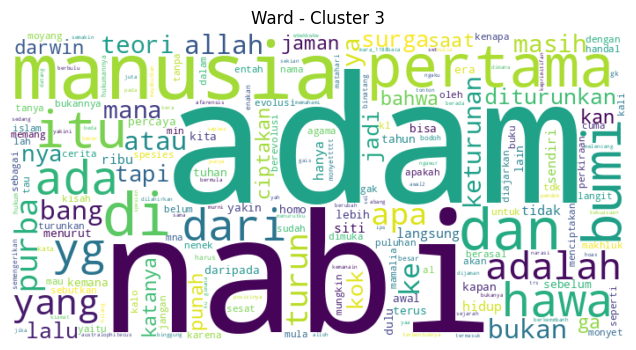

In [15]:
if 'all_labels' not in globals() or 'data_indices' not in globals():
    raise NameError(
        "Jalankan cell clustering terlebih dahulu!"
    )

for key, labels in all_labels.items():

    feature_name, method_name = key

    # Hanya menggunakan TF-IDF
    if feature_name != 'TF-IDF':
        continue

    original_indices = data_indices[key]

    print(f"WordCloud: {feature_name} - {method_name}")

    for cluster_id in sorted(np.unique(labels)):

        selected_indices = original_indices[
            labels == cluster_id
        ]

        cluster_text = ' '.join(
            df_pre.iloc[selected_indices].astype(str).tolist()
        )

        # Menghilangkan karakter selain kata
        clean_text = ' '.join(
            re.findall(r'\b\w+\b', cluster_text.lower())
        )

        # Memeriksa apakah terdapat kata
        if not clean_text.strip():
            print(f"Cluster {cluster_id} tidak memiliki kata.")
            continue

        try:
            wordcloud = WordCloud(
                width=700,
                height=350,
                background_color='white',
                collocations=False
            ).generate(clean_text)

            plt.figure(figsize=(9, 4))
            plt.imshow(wordcloud, interpolation='bilinear')
            plt.axis('off')
            plt.title(
                f'{method_name} - Cluster {cluster_id}'
            )
            plt.show()
            plt.close()

        except ValueError as e:
            print(f"Cluster {cluster_id} dilewati: {e}")

## 13. Menyimpan hasil evaluasi

File CSV hasil perbandingan Silhouette Score dapat diunduh untuk dimasukkan ke laporan.

In [16]:
output_name = 'hasil_perbandingan_clustering_exercise7.csv'
results_df.to_csv(output_name, index=False)
files.download(output_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>